# Real-time ECG cloud monitoring: mini demo
Device (sender) streams a simulated ECG over **MQTT** to the "cloud" (receiver), which plots it live and measures **heart rate, latency and data loss**.



## 1. Install libraries

In [ ]:
!pip install -q neurokit2 paho-mqtt

## 2. Settings and imports
Change `DROP` to e.g. `0.05` to simulate a bad network (5% packets lost).

In [ ]:
import json, random, threading, time, csv
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk
import paho.mqtt.client as mqtt
from scipy.signal import find_peaks
from IPython.display import clear_output

BROKER = "broker.hivemq.com"                      # free public MQTT broker
TOPIC = f"saniya-iitb-demo/ecg/{random.randint(1000, 9999)}"  # unique "channel"
FS = 250          # sampling rate (Hz), typical for ECG
HR = 72           # simulated heart rate (bpm)
SECONDS = 60      # how long to stream
DROP = 0.0        # fraction of packets to drop on purpose (0 to 1)
print("Topic:", TOPIC)

Topic: saniya-iitb-demo/ecg/3069


## 3. The CLOUD side (receiver)
Subscribes to the topic, checks for lost packets using **sequence numbers**, measures **latency** using timestamps, and stores everything (our stand-in for a database).

In [ ]:
WINDOW = 5 * FS                                   # dashboard shows last 5 seconds
signal = deque([0.0] * WINDOW, maxlen=WINDOW)
latencies = []
log_rows = []
stats = {"received": 0, "lost": 0, "expected_seq": None}

def on_connect(client, userdata, flags, reason_code, properties):
    client.subscribe(TOPIC)
    print("Cloud connected and listening")

def on_message(client, userdata, msg):
    t_received = time.time()
    p = json.loads(msg.payload)
    # Data loss: if seq jumps 10 -> 13, packets 11 and 12 were lost
    if stats["expected_seq"] is not None and p["seq"] > stats["expected_seq"]:
        stats["lost"] += p["seq"] - stats["expected_seq"]
    stats["expected_seq"] = p["seq"] + 1
    stats["received"] += 1
    latency_ms = (t_received - p["t_sent"]) * 1000   # how late it arrived
    latencies.append(latency_ms)
    signal.extend(p["samples"])
    log_rows.append([p["seq"], p["t_sent"], t_received, round(latency_ms, 1)])

cloud = mqtt.Client(mqtt.CallbackAPIVersion.VERSION2)
cloud.on_connect = on_connect
cloud.on_message = on_message
cloud.connect(BROKER, 1883)
cloud.loop_start()
time.sleep(2)

Cloud connected and listening


## 4. The DEVICE side (sender, plays the Raspberry Pi)
Generates a realistic ECG and publishes it in 0.1 s packets, each with a sequence number and timestamp.

In [ ]:
def run_device():
    ecg = nk.ecg_simulate(duration=SECONDS, sampling_rate=FS, heart_rate=HR,
                          noise=0.05, random_state=42)
    dev = mqtt.Client(mqtt.CallbackAPIVersion.VERSION2)
    dev.connect(BROKER, 1883)
    dev.loop_start()
    batch = FS // 10                                   # 25 samples = 0.1 s
    for seq, start in enumerate(range(0, len(ecg), batch)):
        packet = {"seq": seq, "t_sent": time.time(),
                  "samples": [round(float(v), 4) for v in ecg[start:start + batch]]}
        if random.random() >= DROP:                    # simulate unreliable network
            dev.publish(TOPIC, json.dumps(packet), qos=0)
        time.sleep(batch / FS)                         # real-time pace
    dev.loop_stop(); dev.disconnect()

device = threading.Thread(target=run_device, daemon=True)
device.start()
print("Device started streaming...")

Device started streaming...


## 5. Live dashboard
Run this right after step 4. It refreshes twice a second until streaming ends.

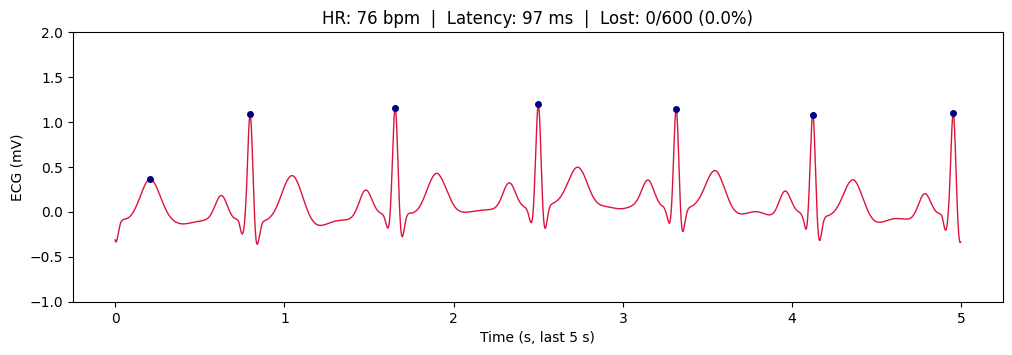

Streaming finished.


In [ ]:
def heart_rate(x):
    x = np.asarray(x)
    peaks, _ = find_peaks(x, distance=int(0.4 * FS), prominence=0.5 * np.std(x) + 1e-6)
    if len(peaks) < 2:
        return None, peaks
    return 60 / np.mean(np.diff(peaks) / FS), peaks

t_axis = np.arange(WINDOW) / FS
while device.is_alive():
    data = np.array(signal)
    hr, peaks = heart_rate(data)
    total = stats["received"] + stats["lost"]
    loss = 100 * stats["lost"] / total if total else 0
    lat = np.mean(latencies[-50:]) if latencies else 0
    clear_output(wait=True)
    plt.figure(figsize=(12, 3.5))
    plt.plot(t_axis, data, color="crimson", lw=1)
    plt.plot(t_axis[peaks], data[peaks], "o", color="navy", ms=4)
    plt.ylim(-1, 2); plt.xlabel("Time (s, last 5 s)"); plt.ylabel("ECG (mV)")
    plt.title(f"HR: {hr:.0f} bpm  |  Latency: {lat:.0f} ms  |  Lost: {stats['lost']}/{total} ({loss:.1f}%)"
              if hr else f"Waiting for data... received {stats['received']}")
    plt.show()
    time.sleep(0.5)
print("Streaming finished.")

## 6. Results summary
Saves the log (our 'database') and shows how latency was distributed.

Packets received : 600
Packets lost     : 0  (0.0%)
Latency  mean    : 94 ms
Latency  95th pct: 113 ms


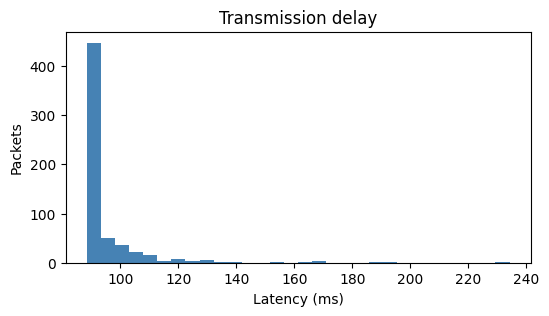

In [ ]:
time.sleep(1)
cloud.loop_stop(); cloud.disconnect()
with open("ecg_log.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["seq", "t_sent", "t_received", "latency_ms"]); w.writerows(log_rows)

total = stats["received"] + stats["lost"]
print(f"Packets received : {stats['received']}")
print(f"Packets lost     : {stats['lost']}  ({100*stats['lost']/max(total,1):.1f}%)")
print(f"Latency  mean    : {np.mean(latencies):.0f} ms")
print(f"Latency  95th pct: {np.percentile(latencies, 95):.0f} ms")
plt.figure(figsize=(6, 3)); plt.hist(latencies, bins=30, color="steelblue")
plt.xlabel("Latency (ms)"); plt.ylabel("Packets"); plt.title("Transmission delay"); plt.show()